# EMG Processing of Hand Movements — Kaggle "EMG Signal for Gesture Recognition"

This notebook runs a complete surface-EMG processing pipeline on a **real, public hand-movement dataset** from Kaggle:

> **Dataset:** [`sojanprajapati/emg-signal-for-gesture-recognition`](https://www.kaggle.com/datasets/sojanprajapati/emg-signal-for-gesture-recognition) — a Kaggle mirror of the UCI *EMG Data for Gestures* dataset (Lobov et al., 2018; CC BY 4.0).

| Property | Value |
|---|---|
| Device | Myo Thalmic armband — 8 dry electrodes equally spaced around the **forearm** |
| Subjects | 36 (each performed the protocol **twice** → 72 recordings) |
| Sampling | nominal **200 Hz** raw EMG (logged at ~1 kHz timestamps with repeated values — see Section 3) |
| Units | volts in the CSV (8-bit ADC, ±1.28 mV) — converted to **µV** here |
| Gestures | 1 rest · 2 fist · 3 wrist flexion · 4 wrist extension · 5 radial deviation · 6 ulnar deviation · 7 extended palm (not all subjects) · 0 = unmarked/transition |

Every gesture is held for ~3 s, followed by ~3 s of rest.

### Pipeline
1. Download & load the data
2. Explore the structure and the **sampling-rate pitfall**
3. Resample to a uniform 200 Hz grid
4. Preprocessing — DC removal → band-pass → mains notch → rectification
5. Envelope detection (moving average, RMS, Hilbert, linear envelope)
6. Muscle-activation patterns per gesture
7. Time- and frequency-domain features per gesture
8. Windowed feature extraction for all 72 recordings
9. Gesture classification — within-subject vs. cross-subject

The same steps are applied to our own BrainAccess recordings in `02_brainaccess_*.ipynb`, so the results can be compared directly.

In [1]:
# Setup: make the repository modules importable regardless of where Jupyter was started.
import sys
from pathlib import Path

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'emg_methods.py').exists())
sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import GroupKFold, cross_val_predict

import emg_methods as em
import emg_io as eio
import emg_plotting as ep

ep.set_style()
DATA_DIR = REPO_ROOT / 'data' / 'kaggle_gestures'
RESULTS_DIR = REPO_ROOT / 'results'
RESULTS_DIR.mkdir(exist_ok=True)
print('Repository root:', REPO_ROOT)

Repository root: /home/michalkubascik/Research/Litva/EMG_signal_processing


## 1. Download and load the dataset

`download_kaggle_dataset` uses the Kaggle CLI if you have API credentials (`~/.kaggle/kaggle.json`, `~/.kaggle/access_token` or `KAGGLE_API_TOKEN`). Otherwise it uses Kaggle's public download endpoint, which works for public datasets without an account. The archive (~17 MB zipped, ~280 MB CSV) is downloaded once into `data/kaggle_gestures/`.

In [2]:
eio.download_kaggle_dataset(eio.KAGGLE_GESTURES_SLUG, DATA_DIR, expected_file=eio.GESTURES_CSV_NAME)

df = eio.load_gesture_dataset(DATA_DIR / eio.GESTURES_CSV_NAME)
print('Shape:', df.shape)
df.head()

Dataset already present: /home/michalkubascik/Research/Litva/EMG_signal_processing/data/kaggle_gestures/EMG-data.csv


Shape: (4237907, 12)


,time_ms,ch1,ch2,ch3,ch4,ch5,ch6,ch7,ch8,gesture,subject,recording
0,1,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0,1,0
1,5,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0,1,0
2,6,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0,1,0
3,7,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0,1,0
4,8,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0,1,0


## 2. Data exploration

In [3]:
summary = (
    df.groupby(['subject', 'recording'])
      .agg(rows=('time_ms', 'size'), duration_s=('time_ms', lambda t: (t.max() - t.min()) / 1000))
)
print(f"Subjects: {df['subject'].nunique()}, recordings: {len(summary)}")
print(f"Recording duration: {summary['duration_s'].min():.0f}–{summary['duration_s'].max():.0f} s "
      f"(median {summary['duration_s'].median():.0f} s)")
print('Missing values:', int(df.isna().sum().sum()))

counts = (df['gesture'].value_counts().sort_index()
          .rename(index=eio.GESTURE_NAMES).rename('rows').to_frame())
counts['share_%'] = (100 * counts['rows'] / counts['rows'].sum()).round(1)
counts['subjects'] = df.groupby('gesture')['subject'].nunique().rename(index=eio.GESTURE_NAMES)
counts

Subjects: 36, recordings: 72
Recording duration: 47–97 s (median 60 s)
Missing values: 0


,rows,share_%,subjects
gesture,,,
unmarked,2725157,64.3,36
rest,250055,5.9,36
fist,243193,5.7,36
wrist flexion,249494,5.9,36
wrist extension,251570,5.9,36
radial deviation,251733,5.9,36
ulnar deviation,253009,6.0,36
extended palm,13696,0.3,2


Observations:

* About 64 % of rows are **unmarked** (class 0) — the transitions/pauses between gestures. They are not used for gesture classification.
* **Extended palm** (class 7) was performed by only a few subjects and is excluded from classification to keep classes balanced.
* The six remaining gestures are almost perfectly balanced.

## 3. The sampling-rate pitfall

The CSV has one row per logged millisecond, which suggests 1 kHz sampling. The Myo armband, however, streams raw EMG at **200 Hz** in packets, and the logger repeated the last packet value until a new one arrived. You can check this before any filtering:

Logged rows per second:              962
Rows identical to the previous row:  89 %
Distinct amplitude levels on ch1:    158 (8-bit ADC)


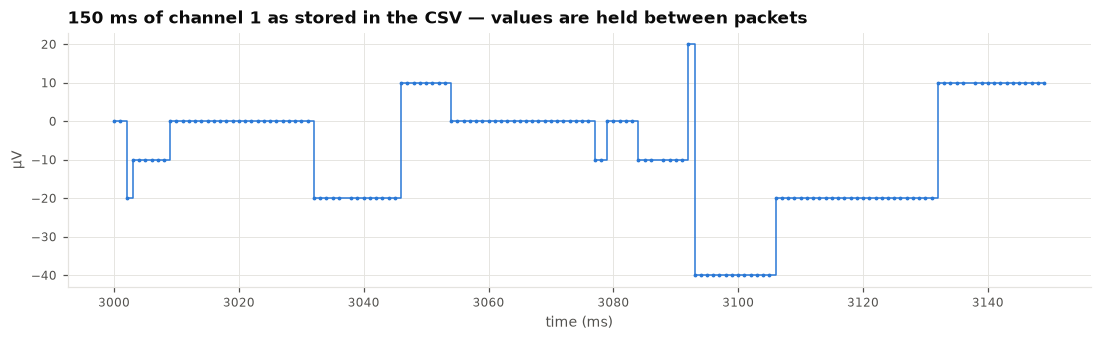

In [4]:
SUBJECT, RECORDING = 1, 0
rec = df[(df['subject'] == SUBJECT) & (df['recording'] == RECORDING)].reset_index(drop=True)

X = rec[eio.MYO_CHANNELS].to_numpy()
repeated = (np.diff(X, axis=0) == 0).all(axis=1).mean()
logged_rate = len(rec) / ((rec['time_ms'].iloc[-1] - rec['time_ms'].iloc[0]) / 1000)
print(f'Logged rows per second:              {logged_rate:.0f}')
print(f'Rows identical to the previous row:  {100 * repeated:.0f} %')
print(f'Distinct amplitude levels on ch1:    {np.unique(X[:, 0]).size} (8-bit ADC)')

seg = rec[(rec['time_ms'] >= 3000) & (rec['time_ms'] < 3150)]
fig, ax = plt.subplots(figsize=(12, 3))
ax.step(seg['time_ms'], seg['ch1'] * 1e6, where='post', color=ep.PALETTE[0], lw=1)
ax.plot(seg['time_ms'], seg['ch1'] * 1e6, '.', color=ep.PALETTE[0], ms=3)
ax.set_title('150 ms of channel 1 as stored in the CSV — values are held between packets', loc='left')
ax.set_xlabel('time (ms)'); ax.set_ylabel('µV')
plt.show()

**Consequences for processing**

* The real information bandwidth is limited by the **200 Hz** device rate → Nyquist frequency **100 Hz**.
* The textbook surface-EMG band of **20–450 Hz cannot be applied**: frequencies above 100 Hz were never measured, and the staircase steps create spurious high-frequency content.
* We therefore resample every recording onto a uniform 200 Hz grid (zero-order hold, which is how the logger itself filled the gaps) and band-pass at **20–90 Hz** (`em.default_emg_band(fs)` clips the upper edge to 90 % of Nyquist).

The same check matters for our **BrainAccess** recordings (250 Hz → Nyquist 125 Hz).

Resampled: 13132 samples at 200 Hz = 65.7 s


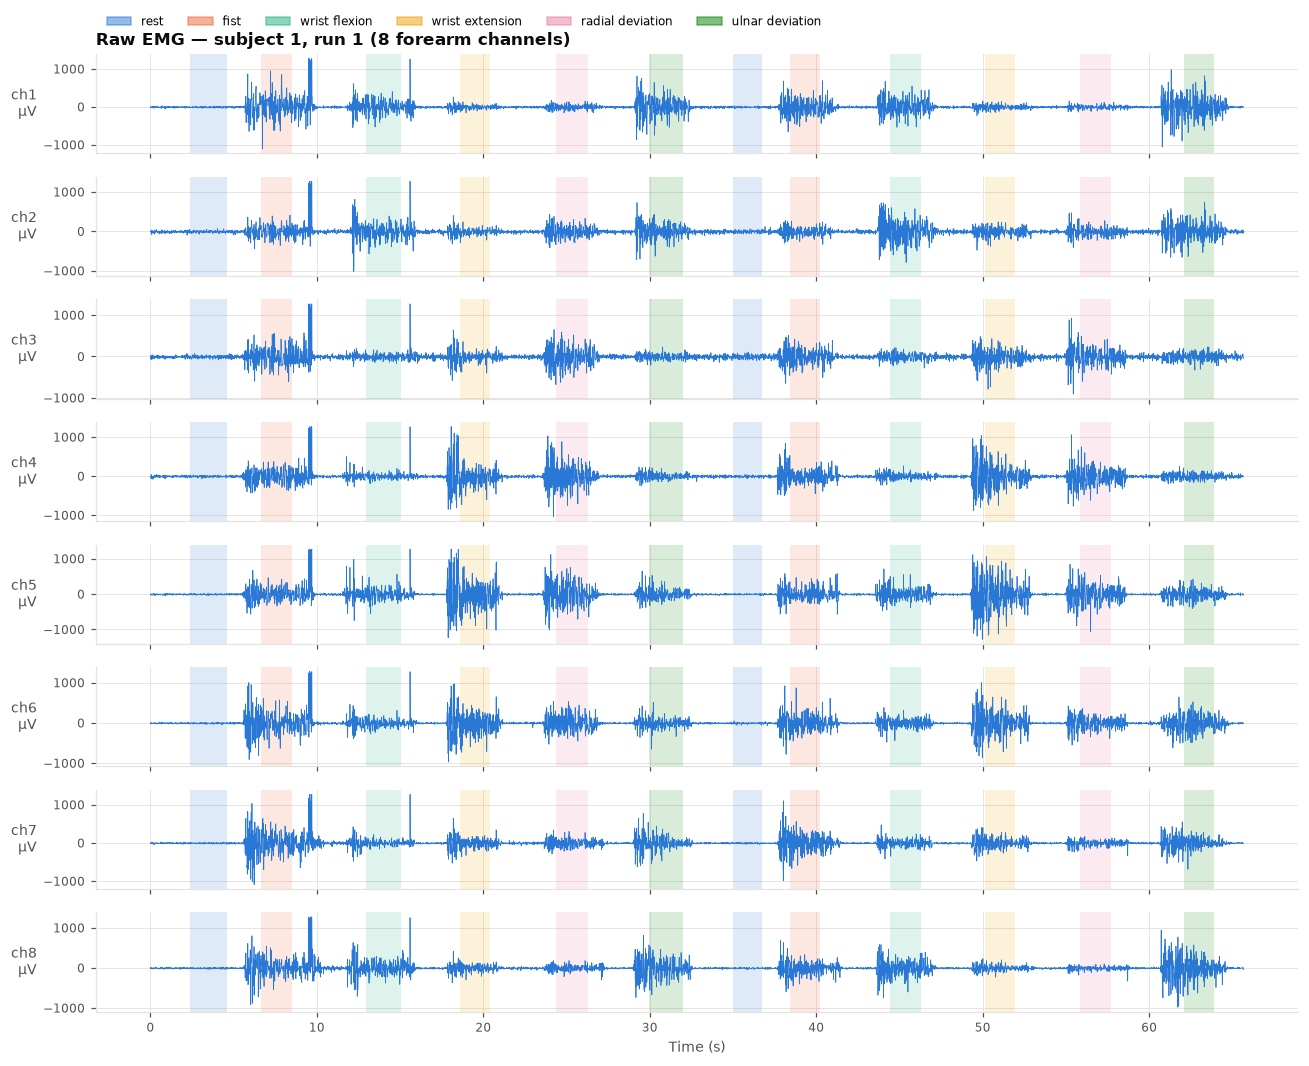

In [5]:
FS = eio.MYO_FS
u = eio.resample_recording(rec, FS)
t = u['t_s'].to_numpy()
emg_raw = u[eio.MYO_CHANNELS].to_numpy().T          # (8, n_samples) in µV
gesture = u['gesture'].to_numpy()

GESTURES = [1, 2, 3, 4, 5, 6]
G_COLORS = ep.label_colors(GESTURES)
G_NAMES = eio.GESTURE_NAMES

print(f'Resampled: {emg_raw.shape[1]} samples at {FS:.0f} Hz = {t[-1]:.1f} s')

fig, axes = ep.plot_channels(t, emg_raw, eio.MYO_CHANNELS, f'Raw EMG — subject {SUBJECT}, run {RECORDING + 1} (8 forearm channels)')
for ax in axes:
    handles = ep.shade_segments(ax, t, gesture, G_COLORS, G_NAMES)
axes[0].legend(handles=handles, ncol=6, loc='lower left', bbox_to_anchor=(0, 1.15))
plt.show()

The shaded intervals mark the labelled gestures. Activation bursts clearly line up with the gestures. Different channels respond to different gestures, because each electrode sits over a different forearm muscle group (wrist flexors on the palmar side, extensors on the dorsal side).

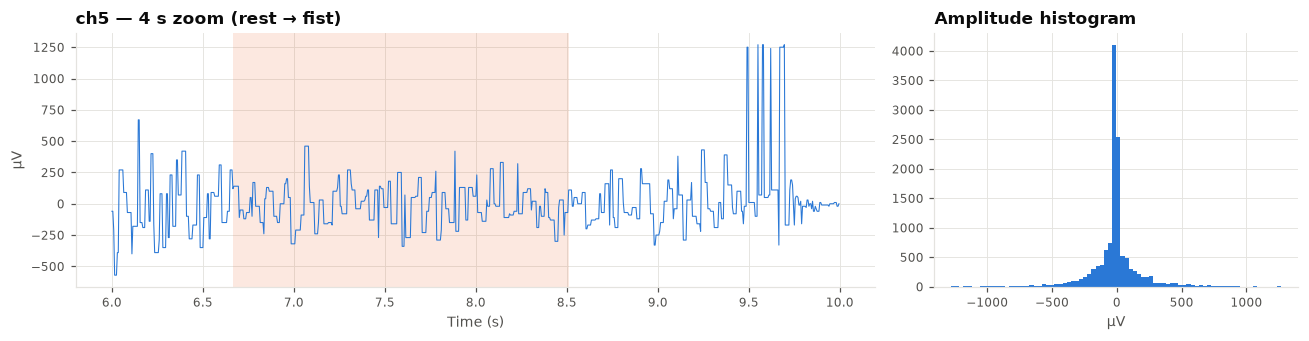

In [6]:
# Zoomed view and amplitude distribution of the most active channel.
ch_idx = int(np.argmax(emg_raw.std(axis=1)))
x_raw = emg_raw[ch_idx]
zoom = (t >= 6) & (t < 10)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={'width_ratios': [2.2, 1]})
axes[0].plot(t[zoom], x_raw[zoom], color=ep.PALETTE[0], lw=0.7)
ep.shade_segments(axes[0], t[zoom], gesture[zoom], G_COLORS, G_NAMES)
axes[0].set_title(f'{eio.MYO_CHANNELS[ch_idx]} — 4 s zoom (rest → fist)', loc='left')
axes[0].set_xlabel('Time (s)'); axes[0].set_ylabel('µV')
axes[1].hist(x_raw, bins=80, color=ep.PALETTE[0])
axes[1].set_title('Amplitude histogram', loc='left'); axes[1].set_xlabel('µV')
fig.tight_layout(); plt.show()

## 4. Preprocessing

| Step | Why |
|---|---|
| **DC offset removal** | centres each channel at zero so amplitude features are not biased |
| **Band-pass 20–90 Hz** (4th-order Butterworth, zero-phase) | removes motion artefacts and drift (< 20 Hz) and stays below Nyquist |
| **Mains notch 50 Hz** | removes power-line interference (Europe; use 60 Hz in the Americas). Harmonics are notched automatically if they lie below Nyquist |
| **Full-wave rectification** | turns the bipolar signal into an amplitude signal for envelope extraction |

All steps are implemented in `emg_methods.preprocess_emg`, which returns every intermediate stage.

Band-pass: 20–90 Hz, notch: 50 Hz


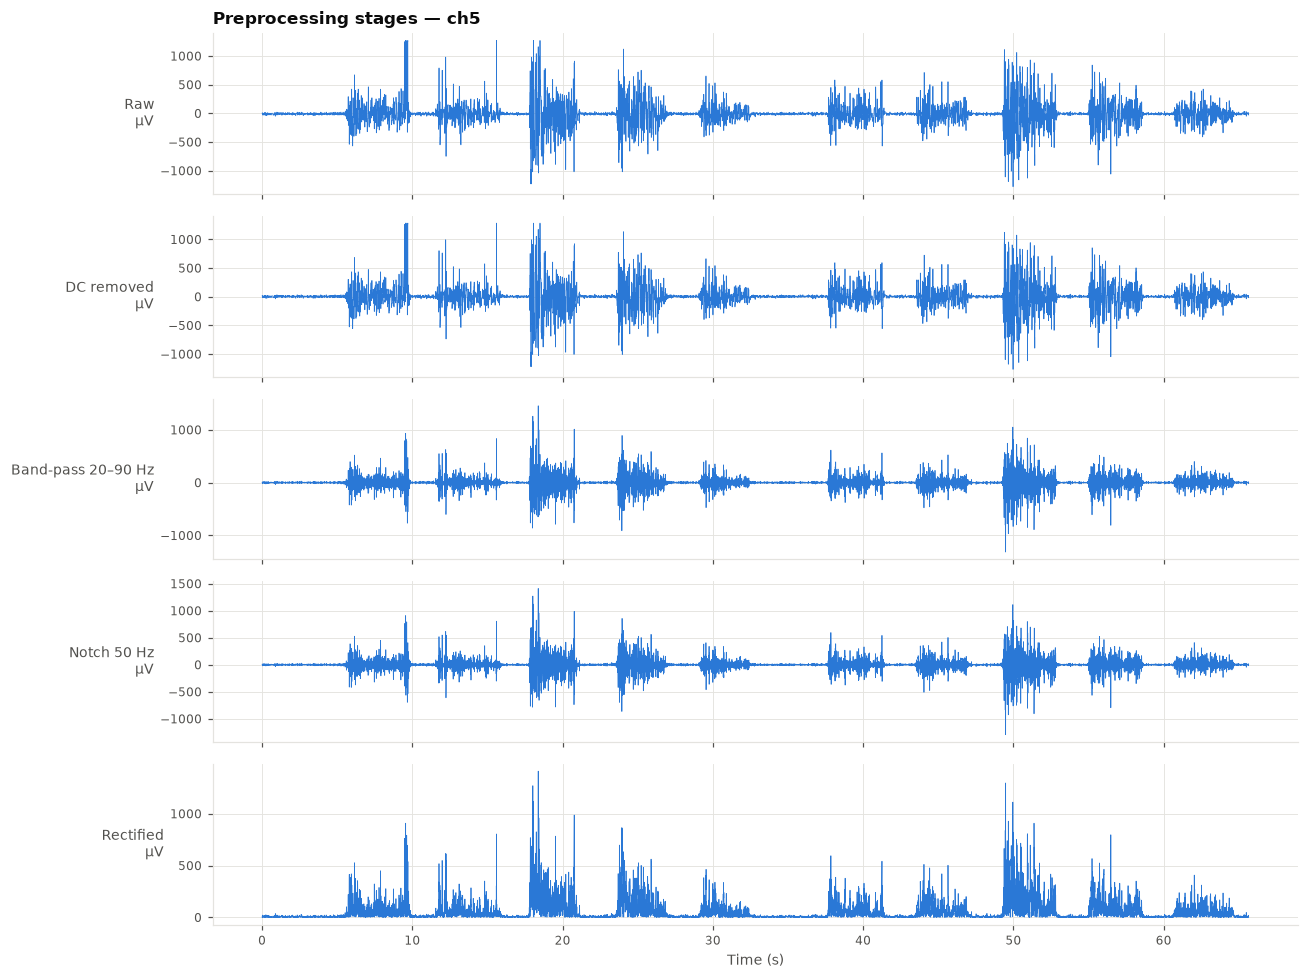

In [7]:
BAND = em.default_emg_band(FS)
MAINS = 50.0
stages = em.preprocess_emg(emg_raw, FS, band=BAND, mains=MAINS)
emg_filt = stages['filtered']
emg_rect = stages['rectified']
print(f'Band-pass: {BAND[0]:.0f}–{BAND[1]:.0f} Hz, notch: {MAINS:.0f} Hz')

names = ['Raw', 'DC removed', f'Band-pass {BAND[0]:.0f}–{BAND[1]:.0f} Hz', 'Notch 50 Hz', 'Rectified']
series = [emg_raw, stages['dc_removed'], stages['bandpassed'], emg_filt, emg_rect]
fig, axes = plt.subplots(len(series), 1, figsize=(12, 9), sharex=True)
for ax, name, s in zip(axes, names, series):
    ax.plot(t, s[ch_idx], color=ep.PALETTE[0], lw=0.5)
    ax.set_ylabel(f'{name}\nµV', rotation=0, ha='right', va='center')
axes[0].set_title(f'Preprocessing stages — {eio.MYO_CHANNELS[ch_idx]}', loc='left')
axes[-1].set_xlabel('Time (s)')
fig.tight_layout(); plt.show()

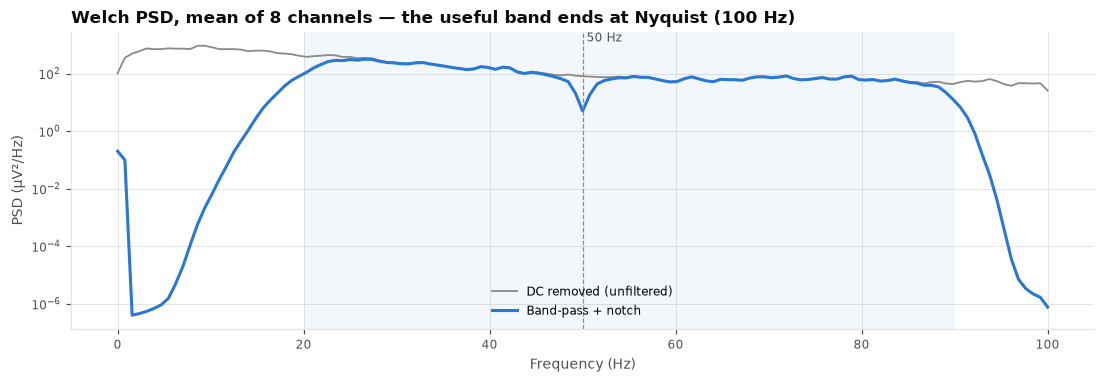

In [8]:
# Power spectral density before and after filtering (all channels averaged).
f_raw, p_raw = em.compute_psd(stages['dc_removed'], FS, nperseg=256)
f_flt, p_flt = em.compute_psd(emg_filt, FS, nperseg=256)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.semilogy(f_raw, p_raw.mean(axis=0), color=ep.INK_MUTED, lw=1.2, label='DC removed (unfiltered)')
ax.semilogy(f_flt, p_flt.mean(axis=0), color=ep.PALETTE[0], lw=2, label='Band-pass + notch')
ax.axvspan(*BAND, color=ep.PALETTE[0], alpha=0.06, lw=0)
ax.axvline(MAINS, color=ep.INK_MUTED, ls='--', lw=0.8)
ax.text(MAINS, 1, ' 50 Hz', transform=ax.get_xaxis_transform(), va='top', fontsize=8, color=ep.INK_SECONDARY)
ax.set_xlabel('Frequency (Hz)'); ax.set_ylabel('PSD (µV²/Hz)')
ax.set_title('Welch PSD, mean of 8 channels — the useful band ends at Nyquist (100 Hz)', loc='left')
ax.legend(); plt.show()

## 5. Envelope detection

The envelope summarises how much the muscle is active over time. Four common methods are compared on the rectified signal:

* **Moving average** — simple; window length sets the smoothness.
* **RMS** — sliding-window root mean square, proportional to signal power.
* **Hilbert** — magnitude of the analytic signal of the *filtered* signal; follows fast changes but stays ripply.
* **Linear envelope** — 5 Hz low-pass of the rectified signal, the standard in biomechanics.

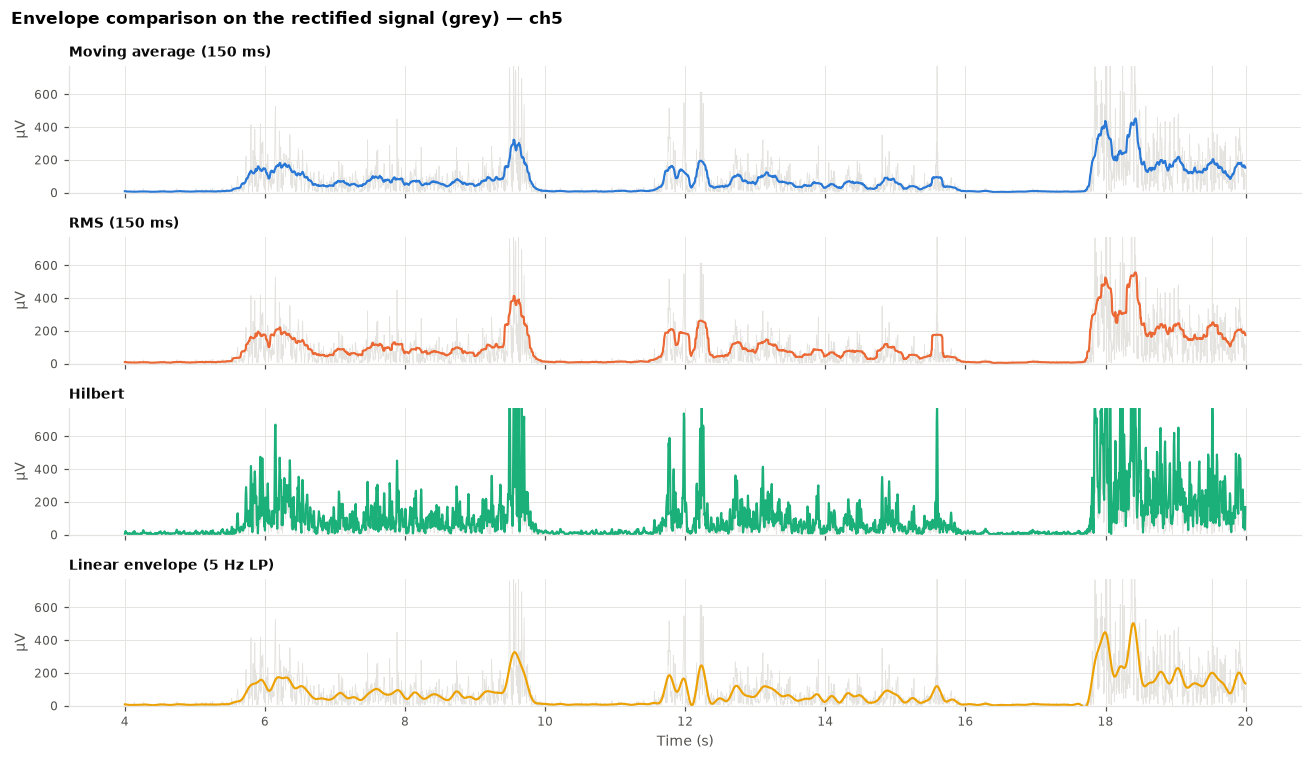

In [9]:
WIN_ENV = int(0.15 * FS)   # 150 ms
x_f, x_r = emg_filt[ch_idx], emg_rect[ch_idx]
env = {
    'Moving average (150 ms)': em.moving_average_envelope(x_r, WIN_ENV),
    'RMS (150 ms)': em.rms_envelope(x_f, WIN_ENV),
    'Hilbert': em.hilbert_envelope(x_f),
    'Linear envelope (5 Hz LP)': em.lowpass_envelope(x_f, FS, cutoff=5),
}

view = (t >= 4) & (t < 20)
fig, axes = plt.subplots(len(env), 1, figsize=(12, 7), sharex=True, sharey=True)
for ax, (name, e), c in zip(axes, env.items(), ep.PALETTE):
    ax.plot(t[view], x_r[view], color=ep.GRID, lw=0.5)
    ax.plot(t[view], e[view], color=c, lw=1.4)
    ax.set_title(name, loc='left', fontsize=9)
    ax.set_ylabel('µV')
axes[0].set_ylim(0, np.percentile(x_r, 99.8))
axes[-1].set_xlabel('Time (s)')
fig.suptitle(f'Envelope comparison on the rectified signal (grey) — {eio.MYO_CHANNELS[ch_idx]}', x=0.01, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout(); plt.show()

The moving-average, RMS and linear envelopes give smooth activation curves that can be compared directly. The Hilbert envelope of a broadband signal like EMG keeps almost all of its ripple, so it needs extra low-pass smoothing before it is usable for onset detection.

## 6. Muscle-activation patterns per gesture

The RMS of each channel during each gesture gives a spatial *activation map* of the forearm. This spatial pattern is what lets a classifier tell the gestures apart. We compute it first for one recording, then averaged over all 72 recordings (each recording normalised to its own maximum, because amplitude varies strongly between subjects).

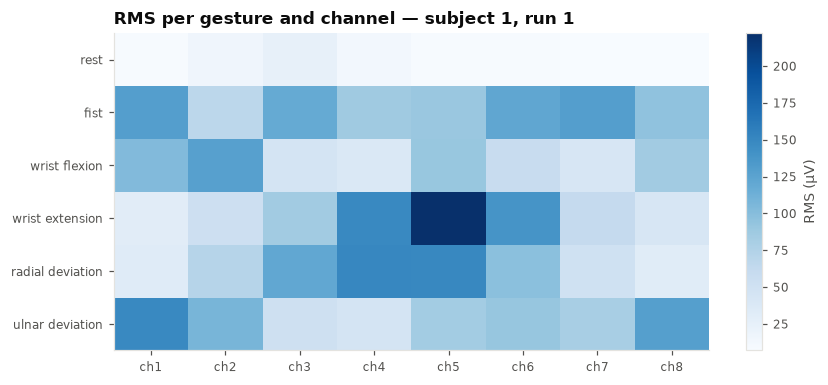

In [10]:
def gesture_rms_map(filtered: np.ndarray, labels: np.ndarray) -> pd.DataFrame:
    rows = {G_NAMES[g]: np.sqrt(np.mean(filtered[:, labels == g] ** 2, axis=1)) for g in GESTURES if np.any(labels == g)}
    return pd.DataFrame(rows, index=eio.MYO_CHANNELS).T

def show_heatmap(m: pd.DataFrame, title: str, unit: str):
    fig, ax = plt.subplots(figsize=(8, 3.6))
    im = ax.imshow(m.to_numpy(), cmap=ep.SEQUENTIAL_CMAP, aspect='auto')
    ax.grid(False)
    ax.set_xticks(range(m.shape[1]), m.columns); ax.set_yticks(range(m.shape[0]), m.index)
    ax.set_title(title, loc='left')
    fig.colorbar(im, ax=ax, label=unit); fig.tight_layout(); plt.show()

show_heatmap(gesture_rms_map(emg_filt, gesture), f'RMS per gesture and channel — subject {SUBJECT}, run {RECORDING + 1}', 'RMS (µV)')

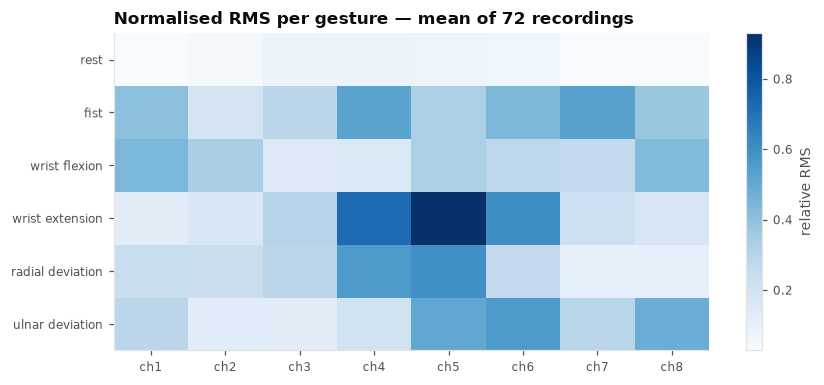

In [11]:
# Process every recording once: resample -> filter. Reused for the group map and the classifier.
processed = {}
for (subj, run), r in df.groupby(['subject', 'recording']):
    ur = eio.resample_recording(r, FS)
    processed[(subj, run)] = (
        em.preprocess_emg(ur[eio.MYO_CHANNELS].to_numpy().T, FS, band=BAND, mains=MAINS)['filtered'],
        ur['gesture'].to_numpy(),
    )

maps = []
for filt, lab in processed.values():
    m = gesture_rms_map(filt, lab)
    maps.append(m / m.to_numpy().max())
group_map = pd.concat(maps).groupby(level=0).mean().loc[[G_NAMES[g] for g in GESTURES]]
show_heatmap(group_map, f'Normalised RMS per gesture — mean of {len(maps)} recordings', 'relative RMS')

**Interpretation.** *Rest* is quiet on every channel. *Fist* activates almost the whole forearm (co-contraction of flexors and extensors). *Wrist flexion* and *wrist extension* activate opposite sides of the armband. *Radial* and *ulnar deviation* produce weaker patterns that partly overlap with extension and flexion, because the same muscles take part: extensor carpi radialis in both extension and radial deviation, flexor carpi ulnaris in both flexion and ulnar deviation.

Note: the armband was worn in roughly the same orientation by each subject, but small rotations shift the pattern between channels. This is one reason why cross-subject classification is harder (Section 9).

## 7. Time- and frequency-domain features per gesture

Classic EMG descriptors (see `docs/03_preprocessing_and_features.md`) are computed on the **filtered, non-rectified** signal of the selected channel for every gesture segment of this recording. ZC and SSC count sign changes, so they are only meaningful before rectification.

In [12]:
WAMP_THR = 0.1 * emg_filt[ch_idx].std()     # adaptive threshold (µV)
rows = []
for g in GESTURES:
    seg = emg_filt[ch_idx, gesture == g]
    if seg.size < 64:
        continue
    feats = em.compute_time_domain_features(seg, wamp_threshold=WAMP_THR)
    feats.update(em.compute_frequency_domain_features(seg, FS, nperseg=128))
    # IEMG, energy, WL, ZC, SSC and WAMP scale with segment length -> report them per second.
    dur = seg.size / FS
    for k in ['IEMG', 'Signal Energy', 'WL', 'ZC', 'SSC', 'WAMP']:
        feats[k] /= dur
    rows.append({'gesture': G_NAMES[g], **feats})

feature_table = pd.DataFrame(rows).set_index('gesture')
feature_table.rename(columns={k: f'{k} /s' for k in ['IEMG', 'Signal Energy', 'WL', 'ZC', 'SSC', 'WAMP']}).round(2)

,MAV,RMS,Variance,Std,IEMG /s,WL /s,ZC /s,SSC /s,WAMP /s,Peak Amplitude,Signal Energy /s,MNF,MDF,Peak Frequency,Total Spectral Power
gesture,,,,,,,,,,,,,,,
rest,6.06,7.91,62.60,7.91,1211.41,1277.62,78.42,107.79,32.69,28.72,12520.68,42.40,35.94,28.12,35.11
fist,67.13,90.04,8106.71,90.04,13426.27,15281.33,77.64,113.03,174.21,448.71,1621353.75,44.18,35.94,34.38,5107.65
wrist flexion,64.10,90.29,8152.47,90.29,12819.86,14223.44,75.73,108.51,165.95,501.97,1630494.86,44.20,35.94,26.56,5070.89
wrist extension,165.37,222.31,49421.03,222.31,33073.44,36182.81,77.12,112.43,187.85,907.77,9884210.10,41.66,35.94,23.44,33151.87
radial deviation,109.83,149.66,22399.16,149.66,21965.88,24656.25,75.70,110.23,184.59,795.98,4479832.20,43.05,34.38,23.44,15635.65
ulnar deviation,60.28,84.24,7096.60,84.24,12055.67,13406.39,76.63,115.45,167.31,338.79,1419321.45,42.65,34.38,25.00,4196.38


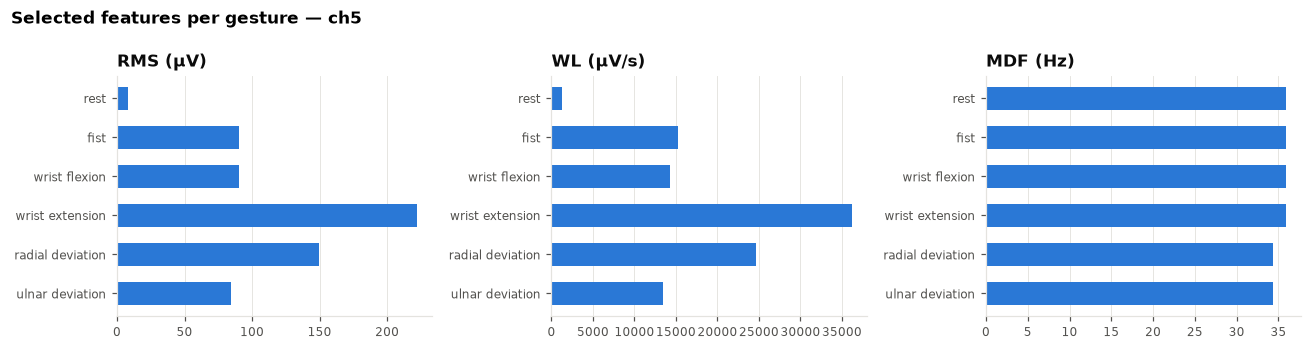

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, unit in zip(axes, ['RMS', 'WL', 'MDF'], ['µV', 'µV/s', 'Hz']):
    vals = feature_table[col]
    ax.barh(vals.index, vals.to_numpy(), color=ep.PALETTE[0], height=0.6)
    ax.invert_yaxis(); ax.set_title(f'{col} ({unit})', loc='left')
    ax.grid(axis='y', visible=False)
fig.suptitle(f'Selected features per gesture — {eio.MYO_CHANNELS[ch_idx]}', x=0.01, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout(); plt.show()

* **RMS / MAV / WL** scale with contraction intensity. Rest is lowest, and the gestures that load this muscle are highest.
* **MDF / MNF** describe the spectral content. At 200 Hz sampling they are compressed into the 20–90 Hz band, so differences between gestures are small. Absolute values cannot be compared with studies sampled at ≥ 1 kHz (typical MDF 60–120 Hz).

## 8. Windowed feature extraction (all recordings)

For classification the signal is cut into **250 ms windows with 125 ms step** (50 % overlap). This is a typical latency budget for prosthesis control. For each of the 8 channels we compute MAV, RMS, VAR, WL, ZC, SSC, WAMP, MNF and MDF, which gives 72 features per window. A window gets a gesture label only if it lies completely inside one gesture.

In [14]:
WIN, STEP = int(0.25 * FS), int(0.125 * FS)
frames = []
for (subj, run), (filt, lab) in processed.items():
    F = em.windowed_features(filt, FS, WIN, STEP, eio.MYO_CHANNELS)
    start = F['start'].to_numpy()
    first, last = lab[start], lab[start + WIN - 1]
    F['gesture'] = np.where(first == last, first, -1)
    F['subject'], F['recording'] = subj, run
    frames.append(F)

features = pd.concat(frames, ignore_index=True)
features = features[features['gesture'].isin(GESTURES)].reset_index(drop=True)
FEATURE_COLS = [c for c in features.columns if c.startswith('ch')]
features.to_csv(RESULTS_DIR / 'kaggle_gestures_window_features.csv', index=False)
print(f'{len(features)} labelled windows × {len(FEATURE_COLS)} features')
features['gesture'].map(G_NAMES).value_counts()

10731 labelled windows × 72 features


gesture
ulnar deviation     1814
wrist extension     1810
radial deviation    1805
wrist flexion       1789
rest                1786
fist                1727
Name: count, dtype: int64

## 9. Gesture classification

A Random Forest is trained on the window features. Two evaluation schemes answer different questions:

1. **Session transfer (within the same people):** train on everyone's first run, test on their second run.
2. **Cross-subject:** 5-fold `GroupKFold` by subject. The test subjects are never seen during training, which is the realistic "plug-and-play" scenario.

Splitting windows randomly would leak overlapping windows from the same contraction into train and test, and would overestimate accuracy.

In [15]:
clf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)
y = features['gesture'].to_numpy()
Xf = features[FEATURE_COLS]

train = features['recording'] == 0
clf.fit(Xf[train], y[train])
pred_session = clf.predict(Xf[~train])
print(f"Run 1 -> run 2 (same subjects):  accuracy {accuracy_score(y[~train], pred_session):.3f}")

pred_cross = cross_val_predict(clf, Xf, y, groups=features['subject'], cv=GroupKFold(n_splits=5))
print(f"Cross-subject (GroupKFold=5):    accuracy {accuracy_score(y, pred_cross):.3f}, "
      f"balanced {balanced_accuracy_score(y, pred_cross):.3f}")
print(f"Chance level:                    {1 / len(GESTURES):.3f}")

Run 1 -> run 2 (same subjects):  accuracy 0.890


Cross-subject (GroupKFold=5):    accuracy 0.833, balanced 0.833
Chance level:                    0.167


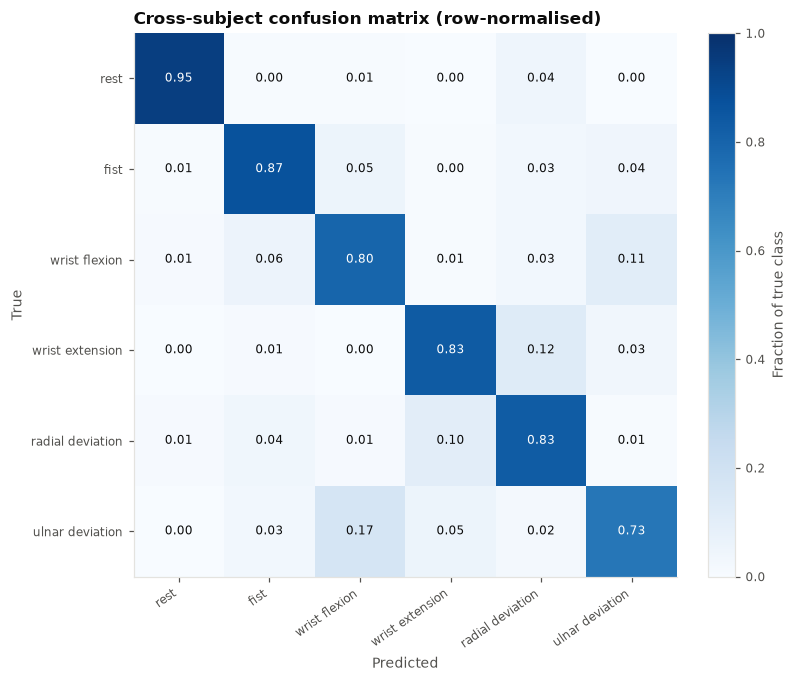

In [16]:
labels_txt = [G_NAMES[g] for g in GESTURES]
ep.plot_confusion(confusion_matrix(y, pred_cross, labels=GESTURES), labels_txt, 'Cross-subject confusion matrix (row-normalised)')
plt.show()

Rest is recognised almost perfectly, because its amplitude alone separates it. Most errors occur between gestures that share muscles: **ulnar deviation ↔ wrist flexion** (flexor carpi ulnaris) and **radial deviation ↔ wrist extension** (extensor carpi radialis). This matches the activation maps in Section 6.

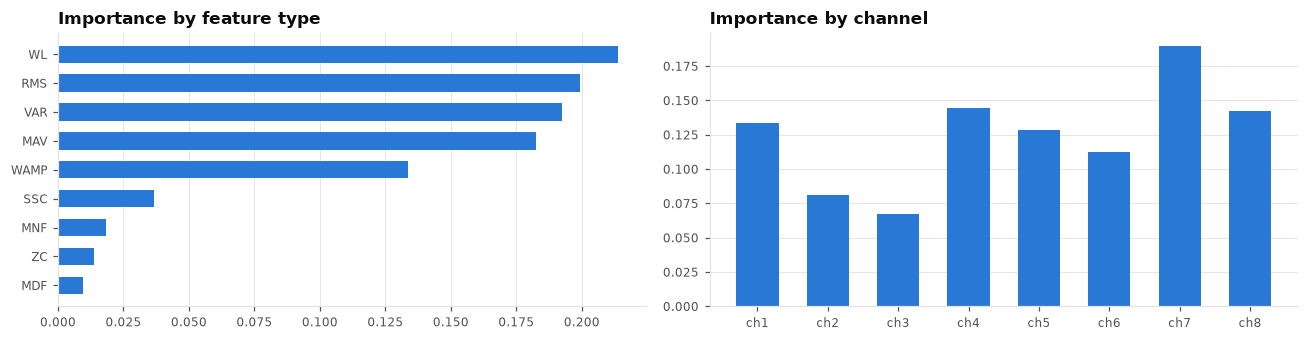

In [17]:
# Which features matter most? Aggregate impurity importance by feature type and by channel.
clf.fit(Xf, y)
imp = pd.Series(clf.feature_importances_, index=FEATURE_COLS)
by_feature = imp.groupby(lambda c: c.split('_')[1]).sum().sort_values()
by_channel = imp.groupby(lambda c: c.split('_')[0]).sum().reindex(eio.MYO_CHANNELS)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].barh(by_feature.index, by_feature.to_numpy(), color=ep.PALETTE[0], height=0.6)
axes[0].set_title('Importance by feature type', loc='left'); axes[0].grid(axis='y', visible=False)
axes[1].bar(by_channel.index, by_channel.to_numpy(), color=ep.PALETTE[0], width=0.6)
axes[1].set_title('Importance by channel', loc='left'); axes[1].grid(axis='x', visible=False)
fig.tight_layout(); plt.show()

## 10. Conclusions

* **Always verify the true sampling rate.** The CSV looks like 1 kHz but carries 200 Hz data. Filtering it with the standard 20–450 Hz band would be wrong.
* After DC removal, a 20–90 Hz band-pass and a 50 Hz notch, the envelopes clearly show each gesture as an activation burst.
* The **spatial pattern** of RMS over the 8 forearm channels is specific to each gesture. Amplitude features (WL, RMS, VAR, MAV, WAMP) carry most of the discriminative information, while spectral features (MNF, MDF) and ZC add little at this low sampling rate.
* Classification is good when the model has seen the person before, and drops for unseen subjects. Differences in anatomy and armband placement are the main obstacle to user-independent EMG control.

**Next:** the same pipeline is applied to our own BrainAccess recordings of the forearm, arm and calf in `02_brainaccess_forearm.ipynb`, `02_brainaccess_arm.ipynb` and `02_brainaccess_calf.ipynb`.

### References
* Lobov S., Krilova N., Kastalskiy I., Kazantsev V., Makarov V. (2018). *Latent factors limiting the performance of sEMG-interfaces.* Sensors 18(4):1122.
* UCI Machine Learning Repository — [EMG Data for Gestures](https://archive.ics.uci.edu/dataset/481/emg+data+for+gestures).
* Phinyomark A., Phukpattaranont P., Limsakul C. (2012). *Feature reduction and selection for EMG signal classification.* Expert Systems with Applications 39(8).